In [1]:
!pip install box2d gymnasium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 4.3 MB/s  0:00:00


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
/usr/lib/python3.13/multiprocessing/popen_fork.py:73: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
Training BipedalWalkerHardcore-v3 (2 GPU | <class 'jax.numpy.float32'>): 3500032it [59:44, 976.47it/s, eval_return=315.1] /usr/lib/python3.13/multiprocessing/popen_fork.py:73: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()



Rendered Episode Score: 319.87


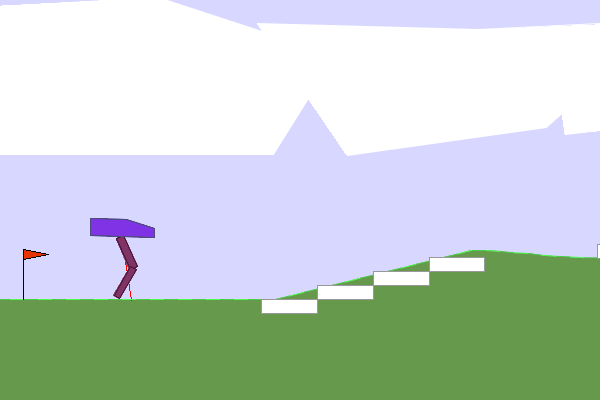

In [2]:
from functools import partial
import os
import flax.linen as nn
import flax.serialization
import gymnasium as gym
import imageio
from IPython.display import Image, display
import jax
from jax.experimental import mesh_utils
import jax.numpy as jnp
from jax.sharding import Mesh, NamedSharding, PartitionSpec as P
import numpy as np
import optax
from tqdm import tqdm

ENV_ID = "BipedalWalkerHardcore-v3"
DEVICES = jax.devices()
NUM_GPUS = len(DEVICES)
IS_MULTI_GPU = NUM_GPUS > 1

if IS_MULTI_GPU:
    N = 64
    B = 512 * NUM_GPUS
    UPD = 24
    CAP = 2_000_000
    STEPS = 3_500_000
    WARM = 30_000
    mesh = Mesh(mesh_utils.create_device_mesh((NUM_GPUS,)), ("data",))
    replicated = NamedSharding(mesh, P())
    sharded = NamedSharding(mesh, P("data"))
else:
    N = 32
    B = 512
    UPD = 16
    CAP = 1_500_000
    STEPS = 3_000_000
    WARM = 25_000
    replicated = None
    sharded = None

GAMMA, TAU, LR = 0.99, 0.005, 3e-4
DROPOUT_RATE = 0.01
REWARD_SCALE = 5.0
COMPUTE_DTYPE = (
    jnp.bfloat16
    if DEVICES[0].platform == "gpu"
    and any(
        k in DEVICES[0].device_kind.lower()
        for k in ("a100", "h100", "h200", "rtx 30", "rtx 40", "rtx 50", "l4", "l40")
    )
    else jnp.float32
)


class HardcoreRewardWrapper(gym.RewardWrapper):

    def reward(self, reward):
        return float(np.clip(reward, -10.0, 10.0)) * REWARD_SCALE


def make_env():
    return HardcoreRewardWrapper(gym.make(ENV_ID))


class Actor(nn.Module):
    out: int
    hidden: tuple = (400, 300)

    @nn.compact
    def __call__(self, x):
        x = x.astype(COMPUTE_DTYPE)
        for h in self.hidden:
            x = nn.Dense(h, dtype=COMPUTE_DTYPE, param_dtype=jnp.float32)(x)
            x = nn.LayerNorm(dtype=COMPUTE_DTYPE, param_dtype=jnp.float32)(x)
            x = nn.relu(x)
        x = nn.Dense(self.out, dtype=COMPUTE_DTYPE, param_dtype=jnp.float32)(x)
        return x.astype(jnp.float32)


class DroQCriticBlock(nn.Module):
    hidden: tuple = (400, 300)

    @nn.compact
    def __call__(self, x, deterministic: bool = False):
        x = x.astype(COMPUTE_DTYPE)
        for h in self.hidden:
            x = nn.Dense(h, dtype=COMPUTE_DTYPE, param_dtype=jnp.float32)(x)
            x = nn.Dropout(rate=DROPOUT_RATE)(x, deterministic=deterministic)
            x = nn.LayerNorm(dtype=COMPUTE_DTYPE, param_dtype=jnp.float32)(x)
            x = nn.relu(x)
        x = nn.Dense(1, dtype=COMPUTE_DTYPE, param_dtype=jnp.float32)(x)
        return x.astype(jnp.float32)[..., 0]


class Critic(nn.Module):

    @nn.compact
    def __call__(self, o, a, deterministic: bool = False):
        x = jnp.concatenate([o, a], -1)
        q1 = DroQCriticBlock()(x, deterministic=deterministic)
        q2 = DroQCriticBlock()(x, deterministic=deterministic)
        return jnp.stack([q1, q2], 0)


def update_obs_stats(mean, var, count, batch):
    batch_mean = jnp.mean(batch, axis=0)
    batch_var = jnp.var(batch, axis=0)
    batch_count = batch.shape[0]
    delta = batch_mean - mean
    tot_count = count + batch_count
    new_mean = mean + delta * (batch_count / tot_count)
    m_a = var * count
    m_b = batch_var * batch_count
    M2 = m_a + m_b + jnp.square(delta) * count * batch_count / tot_count
    new_var = M2 / tot_count
    return new_mean, new_var, tot_count


def normalize_obs(o, mean, var):
    return jnp.clip((o - mean) / jnp.sqrt(var + 1e-6), -10.0, 10.0)


num_workers = min(N, os.cpu_count() or N)
env = gym.vector.AsyncVectorEnv(
    [make_env for _ in range(N)],
    autoreset_mode=gym.vector.AutoresetMode.SAME_STEP,
)
od, ad = env.single_observation_space.shape[0], env.single_action_space.shape[0]
tgt_ent = -float(ad)

actor, critic = Actor(2 * ad), Critic()
key = jax.random.PRNGKey(42)
key, k1, k2, k3 = jax.random.split(key, 4)

ap = actor.init(k1, jnp.zeros((1, od)))
cp = critic.init({"params": k2, "dropout": k3}, jnp.zeros((1, od)), jnp.zeros((1, ad)), deterministic=False)

aopt, copt, lopt = optax.adam(LR), optax.adam(LR), optax.adam(LR)
la0 = jnp.array(np.log(0.2), dtype=jnp.float32)

init_state = dict(
    a=ap,
    c=cp,
    t=cp,
    la=la0,
    ao=aopt.init(ap),
    co=copt.init(cp),
    lo=lopt.init(la0),
    obs_mean=jnp.zeros((od,), jnp.float32),
    obs_var=jnp.ones((od,), jnp.float32),
    obs_count=jnp.array(1e-4, jnp.float32),
    key=key,
)

init_buf = jnp.zeros((CAP, 2 * od + ad + 2), jnp.float32)

if IS_MULTI_GPU:
    state = jax.device_put(init_state, replicated)
    buf = jax.device_put(init_buf, replicated)
else:
    state = jax.device_put(init_state, DEVICES[0])
    buf = jax.device_put(init_buf, DEVICES[0])


def sample(p, o, k):
    mu, ls = jnp.split(actor.apply(p, o), 2, -1)
    ls = jnp.clip(ls, -5.0, 2.0)
    e = jax.random.normal(k, mu.shape)
    u = mu + jnp.exp(ls) * e
    a = jnp.tanh(u)
    lp = (-0.5 * e**2 - ls - 0.9189385).sum(-1)
    lp = lp - (2.0 * (0.6931472 - u - jax.nn.softplus(-2.0 * u))).sum(-1)
    return a, lp


def _train_step(s, buf, size):
    def one(s, _):
        key, k0, k1, k2, kd1, kd2, kd3 = jax.random.split(s["key"], 7)
        idx = jax.random.randint(k0, (B,), 0, size)
        b = buf[idx]
        if IS_MULTI_GPU:
            b = jax.lax.with_sharding_constraint(b, sharded)

        o = normalize_obs(b[:, :od], s["obs_mean"], s["obs_var"])
        a = b[:, od : od + ad]
        r = b[:, od + ad]
        d = b[:, od + ad + 1]
        n = normalize_obs(b[:, od + ad + 2 :], s["obs_mean"], s["obs_var"])

        alpha = jnp.exp(s["la"])
        na, nlp = sample(s["a"], n, k1)
        tq = (
            critic.apply(
                s["t"], n, na, deterministic=False, rngs={"dropout": kd1}
            ).min(0)
            - alpha * nlp
        )
        y = jax.lax.stop_gradient(r + GAMMA * (1.0 - d) * tq)

        def closs(c):
            q_pred = critic.apply(
                c, o, a, deterministic=False, rngs={"dropout": kd2}
            )
            return ((q_pred - y) ** 2).mean(1).sum()

        cg = jax.grad(closs)(s["c"])
        u, co = copt.update(cg, s["co"])
        c = optax.apply_updates(s["c"], u)

        def aloss(p):
            pa, lp = sample(p, o, k2)
            q_val = critic.apply(
                c, o, pa, deterministic=False, rngs={"dropout": kd3}
            ).min(0)
            return (alpha * lp - q_val).mean(), lp

        (_, lp), ag = jax.value_and_grad(aloss, has_aux=True)(s["a"])
        u, ao = aopt.update(ag, s["ao"])
        ap = optax.apply_updates(s["a"], u)

        lg = jax.grad(
            lambda la: -(la * (jax.lax.stop_gradient(lp) + tgt_ent).mean())
        )(s["la"])
        u, lo = lopt.update(lg, s["lo"])
        la = optax.apply_updates(s["la"], u)

        t = optax.incremental_update(c, s["t"], TAU)

        return (
            dict(
                a=ap,
                c=c,
                t=t,
                la=la,
                ao=ao,
                co=co,
                lo=lo,
                obs_mean=s["obs_mean"],
                obs_var=s["obs_var"],
                obs_count=s["obs_count"],
                key=key,
            ),
            None,
        )

    return jax.lax.scan(one, s, None, length=UPD)[0]


def _add_step(buf, row, ptr):
    return buf.at[(ptr + jnp.arange(N)) % CAP].set(row)


def _update_stats_step(s, obs_batch):
    new_mean, new_var, new_count = update_obs_stats(
        s["obs_mean"], s["obs_var"], s["obs_count"], obs_batch
    )
    return {**s, "obs_mean": new_mean, "obs_var": new_var, "obs_count": new_count}


def _act_step(p, o, mean, var, k):
    no = normalize_obs(o, mean, var)
    return sample(p, no, k)[0]


def _act_det_step(p, o, mean, var):
    no = normalize_obs(o, mean, var)
    return jnp.tanh(jnp.split(actor.apply(p, no), 2, -1)[0])


if IS_MULTI_GPU:
    train = jax.jit(
        _train_step,
        in_shardings=(replicated, replicated, None),
        out_shardings=replicated,
    )
    add = jax.jit(
        _add_step,
        donate_argnums=0,
        in_shardings=(replicated, replicated, None),
        out_shardings=replicated,
    )
    update_stats = jax.jit(
        _update_stats_step,
        in_shardings=(replicated, replicated),
        out_shardings=replicated,
    )
    act = jax.jit(
        _act_step,
        in_shardings=(replicated, sharded, replicated, replicated, replicated),
        out_shardings=replicated,
    )
    act_det = jax.jit(
        _act_det_step,
        in_shardings=(replicated, replicated, replicated, replicated),
        out_shardings=replicated,
    )
else:
    train = jax.jit(_train_step)
    add = jax.jit(_add_step, donate_argnums=0)
    update_stats = jax.jit(_update_stats_step)
    act = jax.jit(_act_step)
    act_det = jax.jit(_act_det_step)


def evaluate(s, episodes=5):
    eval_env = gym.make(ENV_ID)
    returns = []
    for ep in range(episodes):
        o, _ = eval_env.reset(seed=100 + ep)
        ep_ret = 0.0
        done = False
        while not done:
            a = np.asarray(
                act_det(
                    s["a"],
                    o[None].astype(np.float32),
                    s["obs_mean"],
                    s["obs_var"],
                )
            )[0]
            o, r, te, tr, _ = eval_env.step(a)
            ep_ret += r
            done = te or tr
        returns.append(ep_ret)
    eval_env.close()
    return float(np.mean(returns))


obs, _ = env.reset(seed=0)
ptr = size = t = 0
best_eval = -float("inf")

pbar = tqdm(
    total=STEPS,
    desc=f"Training {ENV_ID} ({NUM_GPUS} GPU | {COMPUTE_DTYPE})",
)
while t < STEPS:
    obs_f32 = obs.astype(np.float32)
    state = update_stats(state, obs_f32)

    if t < WARM:
        a = env.action_space.sample()
    else:
        key, k = jax.random.split(key)
        a = np.asarray(
            act(state["a"], obs_f32, state["obs_mean"], state["obs_var"], k)
        )

    nobs, rew, term, trunc, info = env.step(a)

    real_next = nobs.copy()
    if "final_obs" in info:
        for i in np.where(info["_final_obs"])[0]:
            real_next[i] = info["final_obs"][i]

    row = np.concatenate(
        [obs_f32, a, rew[:, None], term[:, None], real_next.astype(np.float32)],
        axis=1,
    )

    buf = add(buf, row, ptr)
    ptr = (ptr + N) % CAP
    size = min(size + N, CAP)
    obs = nobs

    t += N
    pbar.update(N)

    if t >= WARM:
        state = train(state, buf, size)

    if t >= WARM and (t % 250_000) < N:
        avg_ret = evaluate(state)
        pbar.set_postfix({"eval_return": f"{avg_ret:.1f}"})
        if avg_ret > best_eval:
            best_eval = avg_ret
            ckpt = {
                "a": jax.device_get(state["a"]),
                "obs_mean": jax.device_get(state["obs_mean"]),
                "obs_var": jax.device_get(state["obs_var"]),
            }
            with open("bipedal_hardcore_best.msgpack", "wb") as f:
                f.write(flax.serialization.to_bytes(ckpt))

pbar.close()
env.close()

final_ckpt = {
    "a": jax.device_get(state["a"]),
    "obs_mean": jax.device_get(state["obs_mean"]),
    "obs_var": jax.device_get(state["obs_var"]),
}
with open("bipedal_hardcore_final.msgpack", "wb") as f:
    f.write(flax.serialization.to_bytes(final_ckpt))

try:
    with open("bipedal_hardcore_best.msgpack", "rb") as f:
        best_ckpt = flax.serialization.from_bytes(final_ckpt, f.read())
except FileNotFoundError:
    best_ckpt = final_ckpt

best_ckpt = jax.device_put(best_ckpt, replicated if IS_MULTI_GPU else DEVICES[0])

renv = gym.make(ENV_ID, render_mode="rgb_array")
o, _ = renv.reset(seed=7)
frames = []
done = False
total_r = 0.0
while not done:
    a = np.asarray(
        act_det(
            best_ckpt["a"],
            o[None].astype(np.float32),
            best_ckpt["obs_mean"],
            best_ckpt["obs_var"],
        )
    )[0]
    o, r, te, tr, _ = renv.step(a)
    total_r += r
    done = te or tr
    frames.append(renv.render())
renv.close()

print(f"Rendered Episode Score: {total_r:.2f}")
imageio.mimsave("bipedal_hardcore.gif", frames[::2], fps=30, loop=0)
display(Image(filename="bipedal_hardcore.gif"))